# CodeAlpha Task 2: Unemployment Analysis with Python

## Objective
This project analyzes unemployment data in India using Python. The analysis covers:

- Data cleaning and preprocessing
- Exploratory data analysis (EDA)
- Unemployment trends over time
- Rural vs Urban unemployment
- State/region-wise patterns
- Impact of COVID-19 on unemployment
- Monthly/seasonal patterns
- Relationship between unemployment and labour participation
- Data-driven economic and social insights

**Dataset:** Unemployment in India.csv  
**Period:** May 2019 to June 2020


In [19]:
!pip install pandas numpy matplotlib seaborn

In [20]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option('display.max_columns', None)
sns.set_theme(style='whitegrid')

print("Libraries imported successfully.")

Libraries imported successfully.


## 1. Load the Dataset

In [21]:
# Load the dataset
file_path = "Unemployment in India.csv"
df = pd.read_csv(file_path)

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (768, 7)


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural


## 2. Data Cleaning and Preprocessing

In [22]:
# Remove extra spaces from column names
df.columns = df.columns.str.strip()

# Convert date column
df['Date'] = pd.to_datetime(df['Date'], dayfirst=True, errors='coerce')

# Convert numerical columns to numeric values
numeric_columns = [
    'Estimated Unemployment Rate (%)',
    'Estimated Employed',
    'Estimated Labour Participation Rate (%)'
]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# Remove duplicate rows
before_duplicates = len(df)
df = df.drop_duplicates()
duplicates_removed = before_duplicates - len(df)

# Check missing values
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate rows removed:", duplicates_removed)
print("Cleaned dataset shape:", df.shape)

Missing values:
Region                                     1
Date                                       1
Frequency                                  1
Estimated Unemployment Rate (%)            1
Estimated Employed                         1
Estimated Labour Participation Rate (%)    1
Area                                       1
dtype: int64

Duplicate rows removed: 27
Cleaned dataset shape: (741, 7)


In [23]:
# Drop rows missing essential analysis fields
required_columns = [
    'Region', 'Date', 'Estimated Unemployment Rate (%)',
    'Estimated Employed', 'Estimated Labour Participation Rate (%)', 'Area'
]

df = df.dropna(subset=required_columns).copy()

# Create useful time columns
df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month
df['Month_Name'] = df['Date'].dt.month_name()

print("Final dataset shape:", df.shape)
df.info()

Final dataset shape: (740, 10)
<class 'pandas.core.frame.DataFrame'>
Index: 740 entries, 0 to 753
Data columns (total 10 columns):
 #   Column                                   Non-Null Count  Dtype         
---  ------                                   --------------  -----         
 0   Region                                   740 non-null    object        
 1   Date                                     740 non-null    datetime64[ns]
 2   Frequency                                740 non-null    object        
 3   Estimated Unemployment Rate (%)          740 non-null    float64       
 4   Estimated Employed                       740 non-null    float64       
 5   Estimated Labour Participation Rate (%)  740 non-null    float64       
 6   Area                                     740 non-null    object        
 7   Year                                     740 non-null    int32         
 8   Month                                    740 non-null    int32         
 9   Month_Name       

## 3. Descriptive Statistics

In [5]:
df[numeric_columns].describe().round(2)

,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%)
count,740.00,740.00,740.00
mean,11.79,7204460.03,42.63
std,10.72,8087988.43,8.11
min,0.00,49420.00,13.33
25%,4.66,1190404.50,38.06
50%,8.35,4744178.50,41.16
75%,15.89,11275489.50,45.50
max,76.74,45777509.00,72.57


In [6]:
print("Number of regions:", df['Region'].nunique())
print("Regions:", sorted(df['Region'].unique()))
print("\nAreas:", df['Area'].unique())
print("\nDate range:", df['Date'].min().date(), "to", df['Date'].max().date())

Number of regions: 28
Regions: ['Andhra Pradesh', 'Assam', 'Bihar', 'Chandigarh', 'Chhattisgarh', 'Delhi', 'Goa', 'Gujarat', 'Haryana', 'Himachal Pradesh', 'Jammu & Kashmir', 'Jharkhand', 'Karnataka', 'Kerala', 'Madhya Pradesh', 'Maharashtra', 'Meghalaya', 'Odisha', 'Puducherry', 'Punjab', 'Rajasthan', 'Sikkim', 'Tamil Nadu', 'Telangana', 'Tripura', 'Uttar Pradesh', 'Uttarakhand', 'West Bengal']

Areas: ['Rural' 'Urban']

Date range: 2019-05-31 to 2020-06-30


## 4. Overall Unemployment Trend

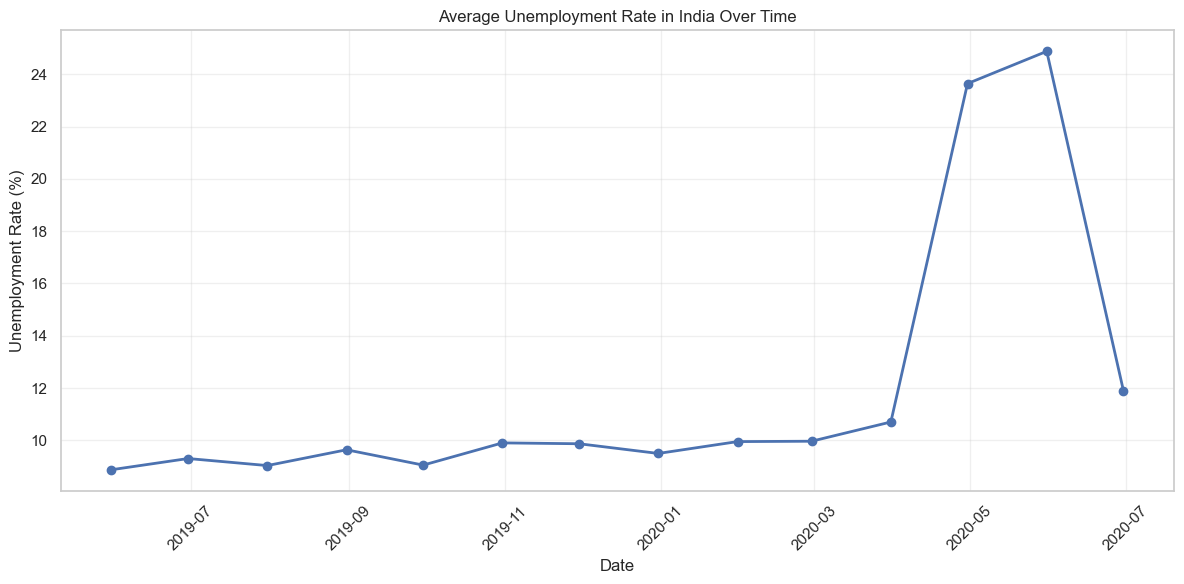

In [7]:
monthly_unemployment = (
    df.groupby('Date')['Estimated Unemployment Rate (%)']
      .mean()
      .sort_index()
)

plt.figure(figsize=(12, 6))
plt.plot(monthly_unemployment.index, monthly_unemployment.values,
         marker='o', linewidth=2)

plt.title('Average Unemployment Rate in India Over Time')
plt.xlabel('Date')
plt.ylabel('Unemployment Rate (%)')
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [8]:
# Print monthly averages
monthly_unemployment.round(2)

Date
2019-05-31     8.87
2019-06-30     9.30
2019-07-31     9.03
2019-08-31     9.64
2019-09-30     9.05
2019-10-31     9.90
2019-11-30     9.87
2019-12-31     9.50
2020-01-31     9.95
2020-02-29     9.96
2020-03-31    10.70
2020-04-30    23.64
2020-05-31    24.88
2020-06-30    11.90
Name: Estimated Unemployment Rate (%), dtype: float64

## 5. Rural vs Urban Analysis

Area
Urban    13.17
Rural    10.32
Name: Estimated Unemployment Rate (%), dtype: float64


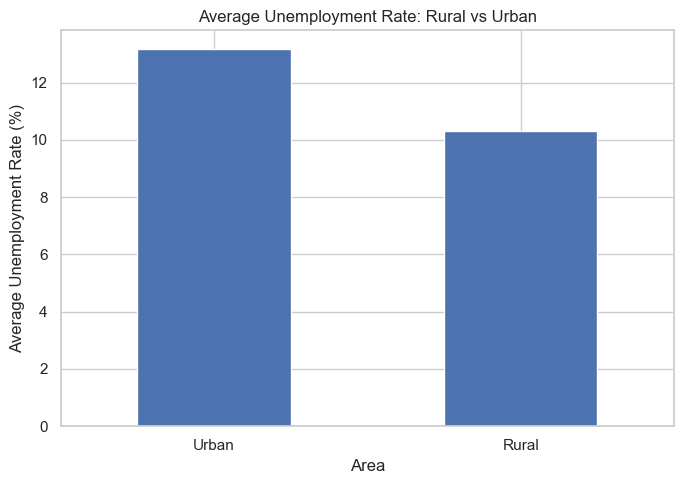

In [9]:
area_average = (
    df.groupby('Area')['Estimated Unemployment Rate (%)']
      .mean()
      .sort_values(ascending=False)
)

print(area_average.round(2))

plt.figure(figsize=(7, 5))
area_average.plot(kind='bar')
plt.title('Average Unemployment Rate: Rural vs Urban')
plt.xlabel('Area')
plt.ylabel('Average Unemployment Rate (%)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 6. Region-wise Unemployment

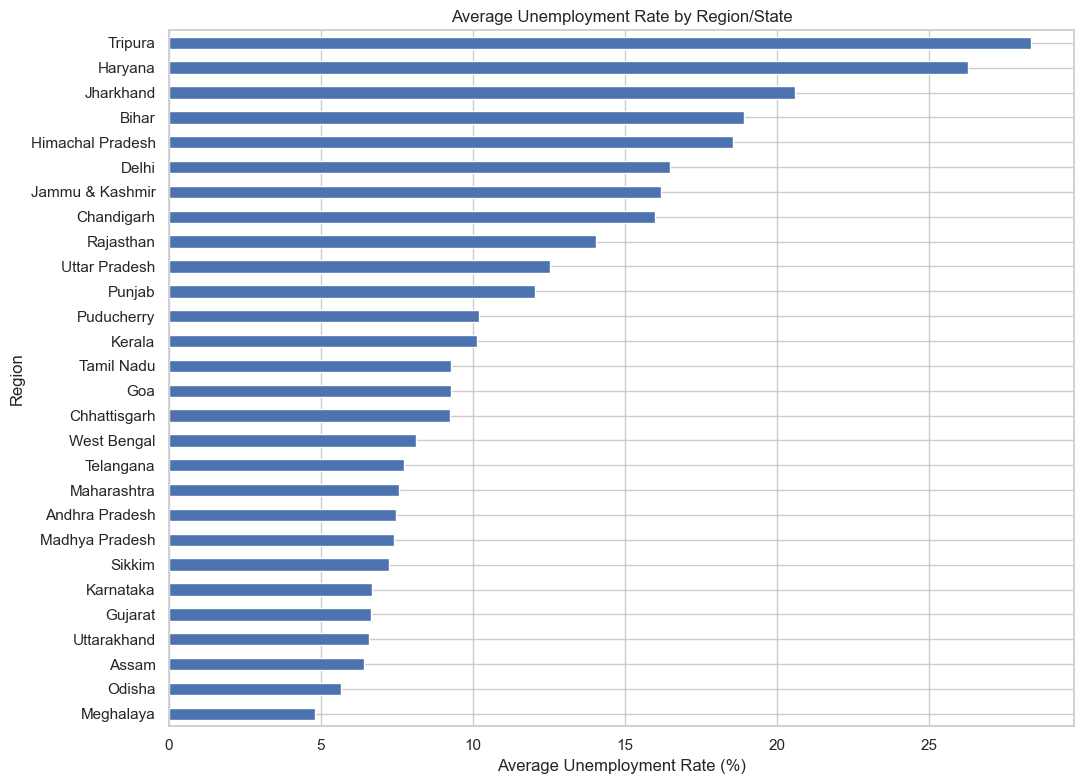

In [10]:
region_average = (
    df.groupby('Region')['Estimated Unemployment Rate (%)']
      .mean()
      .sort_values(ascending=False)
)

plt.figure(figsize=(11, 8))
region_average.plot(kind='barh')
plt.title('Average Unemployment Rate by Region/State')
plt.xlabel('Average Unemployment Rate (%)')
plt.ylabel('Region')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [11]:
print("Top 10 regions by average unemployment:")
display(region_average.head(10).round(2).to_frame('Average Unemployment Rate (%)'))

print("\nBottom 10 regions by average unemployment:")
display(region_average.tail(10).round(2).to_frame('Average Unemployment Rate (%)'))

Top 10 regions by average unemployment:


,Average Unemployment Rate (%)
Region,
Tripura,28.35
Haryana,26.28
Jharkhand,20.58
Bihar,18.92
Himachal Pradesh,18.54
Delhi,16.50
Jammu & Kashmir,16.19
Chandigarh,15.99
Rajasthan,14.06



Bottom 10 regions by average unemployment:


,Average Unemployment Rate (%)
Region,
Maharashtra,7.56
Andhra Pradesh,7.48
Madhya Pradesh,7.41
Sikkim,7.25
Karnataka,6.68
Gujarat,6.66
Uttarakhand,6.58
Assam,6.43
Odisha,5.66


## 7. COVID-19 Impact Analysis

For this dataset, March 2020 is used as the start of the COVID-19 impact period because the nationwide lockdown in India began in March 2020. The comparison is:

- **Pre-COVID:** before March 2020
- **COVID period:** March 2020 onward in the available dataset

This is an analytical comparison, not a claim that every change in unemployment was caused only by COVID-19.

In [12]:
pre_covid = df[df['Date'] < '2020-03-01']
covid_period = df[df['Date'] >= '2020-03-01']

pre_covid_avg = pre_covid['Estimated Unemployment Rate (%)'].mean()
covid_avg = covid_period['Estimated Unemployment Rate (%)'].mean()

absolute_change = covid_avg - pre_covid_avg
percentage_change = (absolute_change / pre_covid_avg) * 100

print(f"Pre-COVID average unemployment: {pre_covid_avg:.2f}%")
print(f"COVID-period average unemployment: {covid_avg:.2f}%")
print(f"Absolute change: {absolute_change:.2f} percentage points")
print(f"Relative change: {percentage_change:.2f}%")

Pre-COVID average unemployment: 9.51%
COVID-period average unemployment: 17.77%
Absolute change: 8.26 percentage points
Relative change: 86.91%


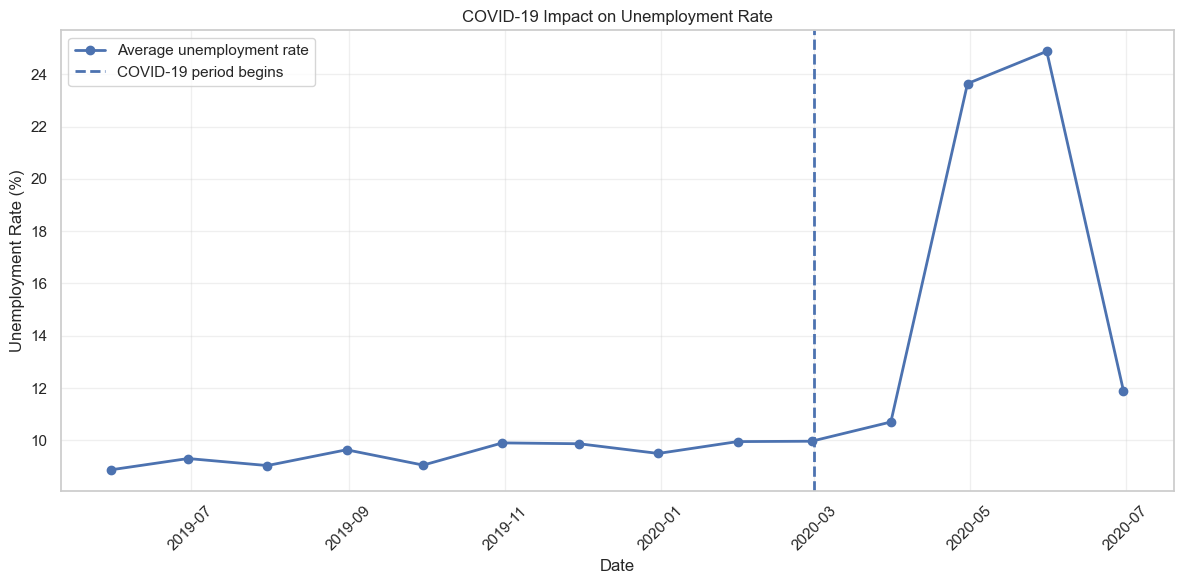

In [13]:
plt.figure(figsize=(12, 6))

plt.plot(monthly_unemployment.index, monthly_unemployment.values,
         marker='o', linewidth=2, label='Average unemployment rate')

plt.axvline(pd.Timestamp('2020-03-01'),
            linestyle='--', linewidth=2, label='COVID-19 period begins')

plt.title('COVID-19 Impact on Unemployment Rate')
plt.xlabel('Date')
plt.ylabel('Unemployment Rate (%)')
plt.xticks(rotation=45)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 8. Monthly Pattern and Possible Seasonality

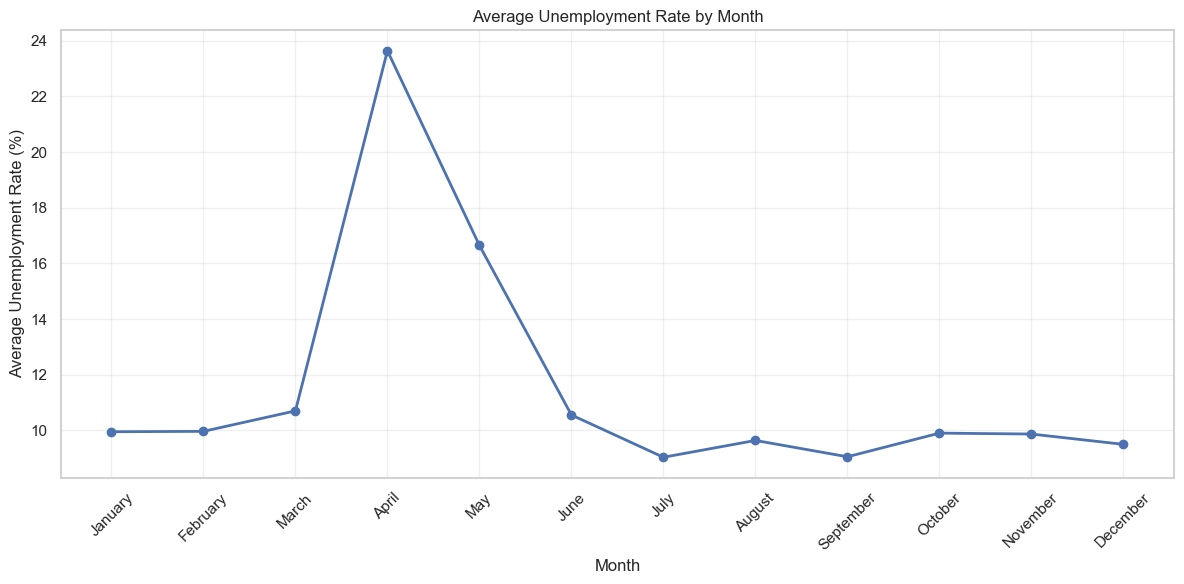

,Average Unemployment Rate (%)
Month,
January,9.95
February,9.96
March,10.70
April,23.64
May,16.65
June,10.55
July,9.03
August,9.64
September,9.05


In [14]:
monthly_pattern = (
    df.groupby('Month')['Estimated Unemployment Rate (%)']
      .mean()
)

month_names = {
    1:'January', 2:'February', 3:'March', 4:'April',
    5:'May', 6:'June', 7:'July', 8:'August',
    9:'September', 10:'October', 11:'November', 12:'December'
}

monthly_pattern.index = monthly_pattern.index.map(month_names)

# Reorder according to calendar
calendar_order = list(month_names.values())
monthly_pattern = monthly_pattern.reindex(calendar_order)

plt.figure(figsize=(12, 6))
plt.plot(monthly_pattern.index, monthly_pattern.values,
         marker='o', linewidth=2)

plt.title('Average Unemployment Rate by Month')
plt.xlabel('Month')
plt.ylabel('Average Unemployment Rate (%)')
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

display(monthly_pattern.round(2).to_frame('Average Unemployment Rate (%)'))

### Important interpretation
The dataset covers only about 14 months, so a strong recurring **seasonal pattern cannot be established statistically**. The large April–May 2020 increase is more appropriately interpreted as a pandemic-period shock than as normal seasonality.

## 9. Highest and Lowest Unemployment Observations

In [15]:
highest = df.loc[df['Estimated Unemployment Rate (%)'].idxmax()]
lowest = df.loc[df['Estimated Unemployment Rate (%)'].idxmin()]

print("Highest unemployment observation:")
display(highest[['Region', 'Date', 'Area', 'Estimated Unemployment Rate (%)']].to_frame().T)

print("\nLowest unemployment observation:")
display(lowest[['Region', 'Date', 'Area', 'Estimated Unemployment Rate (%)']].to_frame().T)

Highest unemployment observation:


,Region,Date,Area,Estimated Unemployment Rate (%)
627,Puducherry,2020-04-30 00:00:00,Urban,76.74



Lowest unemployment observation:


,Region,Date,Area,Estimated Unemployment Rate (%)
25,Assam,2020-06-30 00:00:00,Rural,0.0


## 10. Labour Participation vs Unemployment

,Estimated Unemployment Rate (%),Estimated Labour Participation Rate (%)
Estimated Unemployment Rate (%),1.000,0.003
Estimated Labour Participation Rate (%),0.003,1.000


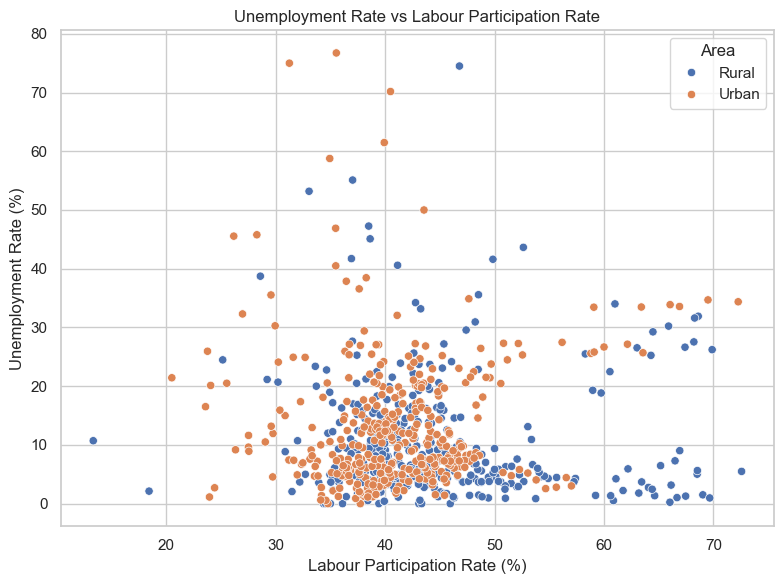

In [16]:
correlation = df[
    ['Estimated Unemployment Rate (%)',
     'Estimated Labour Participation Rate (%)']
].corr()

display(correlation.round(3))

plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=df,
    x='Estimated Labour Participation Rate (%)',
    y='Estimated Unemployment Rate (%)',
    hue='Area'
)

plt.title('Unemployment Rate vs Labour Participation Rate')
plt.xlabel('Labour Participation Rate (%)')
plt.ylabel('Unemployment Rate (%)')
plt.tight_layout()
plt.show()

## 11. Employment Trend

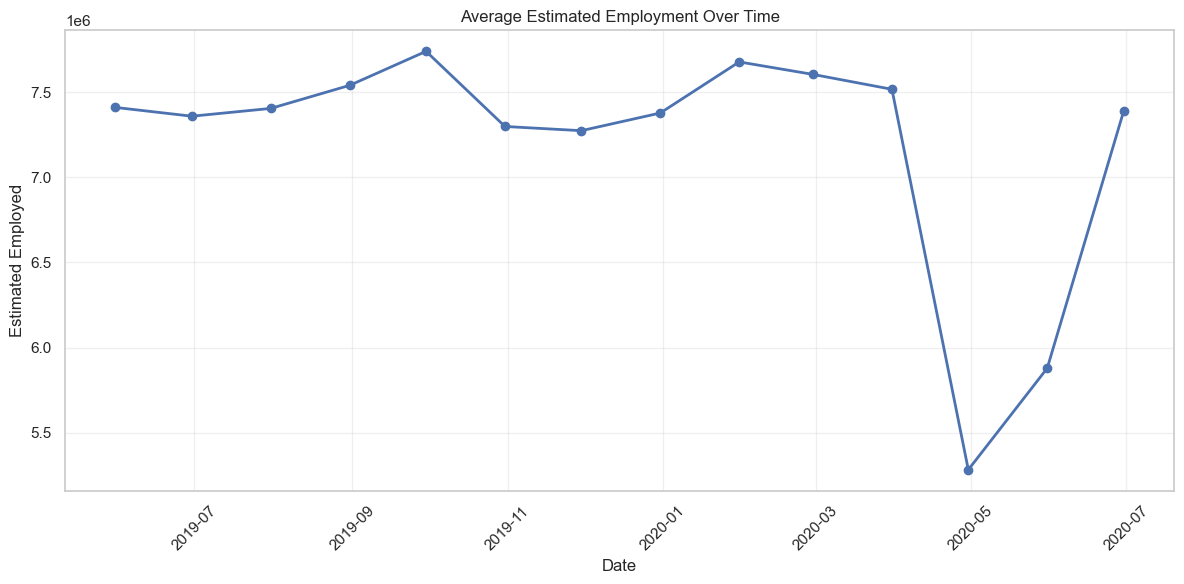

In [17]:
monthly_employment = (
    df.groupby('Date')['Estimated Employed']
      .mean()
      .sort_index()
)

plt.figure(figsize=(12, 6))
plt.plot(monthly_employment.index, monthly_employment.values,
         marker='o', linewidth=2)

plt.title('Average Estimated Employment Over Time')
plt.xlabel('Date')
plt.ylabel('Estimated Employed')
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 12. Key Findings

In [18]:
# Automatically generate important summary statistics
yearly_average = df.groupby('Year')['Estimated Unemployment Rate (%)'].mean()
area_average = df.groupby('Area')['Estimated Unemployment Rate (%)'].mean()

peak_month = monthly_unemployment.idxmax()
peak_value = monthly_unemployment.max()

print("KEY FINDINGS")
print("=" * 50)
print(f"Overall average unemployment: {df['Estimated Unemployment Rate (%)'].mean():.2f}%")
print(f"2019 average unemployment: {yearly_average.get(2019, np.nan):.2f}%")
print(f"2020 average unemployment: {yearly_average.get(2020, np.nan):.2f}%")
print(f"Pre-COVID average: {pre_covid_avg:.2f}%")
print(f"COVID-period average: {covid_avg:.2f}%")
print(f"Peak monthly average: {peak_value:.2f}% ({peak_month.strftime('%B %Y')})")
print(f"Rural average: {area_average.get('Rural', np.nan):.2f}%")
print(f"Urban average: {area_average.get('Urban', np.nan):.2f}%")
print(f"Highest individual observation: {highest['Estimated Unemployment Rate (%)']:.2f}%")
print(f"Highest observation region: {highest['Region']} ({highest['Area']})")

KEY FINDINGS
Overall average unemployment: 11.79%
2019 average unemployment: 9.40%
2020 average unemployment: 15.10%
Pre-COVID average: 9.51%
COVID-period average: 17.77%
Peak monthly average: 24.88% (May 2020)
Rural average: 10.32%
Urban average: 13.17%
Highest individual observation: 76.74%
Highest observation region: Puducherry (Urban)


## 13. Economic and Social Policy Insights

The analysis suggests several areas that can inform further economic and social policy discussion:

1. **Employment support during economic shocks:** The sharp rise during the COVID-19 period shows the importance of temporary employment and income-support mechanisms during major disruptions.

2. **Regional targeting:** Unemployment varies considerably across regions, so employment programs can be monitored at state/region level rather than relying only on national averages.

3. **Rural and urban differences:** Rural and urban areas show different unemployment levels in this dataset. Employment interventions should therefore consider local labour-market conditions.

4. **Skill development:** Training and reskilling programs can help workers adapt when particular sectors experience large employment losses.

5. **Better labour-market monitoring:** More frequent and longer-term data can help distinguish temporary shocks from persistent unemployment and genuine seasonal patterns.

6. **Future analysis:** A longer time series, ideally several years, would be required to establish recurring seasonal effects with greater confidence.

## 14. Conclusion

The unemployment analysis shows a clear change in India's labour-market conditions during the COVID-19 period. The average unemployment rate was substantially higher from March 2020 onward than in the preceding months, with particularly large increases in April and May 2020.

The analysis also reveals differences between rural and urban areas and substantial variation across regions. Because the dataset covers a relatively short period, the monthly pattern should not be treated as proof of normal seasonality; the exceptional April–May 2020 increase is more consistent with a pandemic-related shock.

Overall, Python-based data cleaning, exploratory analysis, and visualization provide a useful way to identify unemployment trends and highlight areas that deserve further economic and social analysis.

## 15. Tools and Technologies

- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Jupyter Notebook

**Project:** CodeAlpha Data Science Internship – Task 2